#### Map ACTib from JSON

In [1]:
import json
import os
import cv2
import json
import fastwer
import shutil
import pyewts
import random
import numpy as np
import matplotlib.pyplot as plt

from tqdm import tqdm
from glob import glob
from pathlib import Path
from evaluate import load
from natsort import natsorted
from Modules import PatchedLineDetection, PatchedPerigLayoutDetection, OnnxInference
from IPython.display import Image as ShowImage
from Exporter import PageXMLExporter
from Utils import create_dir, get_line_images_from_line_data, rotate_from_angle, get_random_color, read_lines_from_file, get_file_name, get_lines_from_page, prepare_ocr_image2, get_line_bbox_centers, group_bbox_centers, resize_to_height, get_line_treshold, get_json, get_line_image_from_bbox, show_image, show_overlay, get_kernel_line

d:\Github\OCR-Inference\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
converter = pyewts.pyewts()
cer_scorer = load("cer")

layout_config = "Models/LayoutModels/Classic/LA_v2_2024-1-22_6-36/model_config.json"
layout_inference = PatchedPerigLayoutDetection(layout_config)

line_model_config = "Models/LineModels/line_model_config.json"
line_inference = PatchedLineDetection(config_file=line_model_config, binarize_output=False, mode="cuda")

models_path = "Models/OCRModels"
dataset = "DergeTenjur"
chkpt_path = "2024_1_30_9_38"
ocr_model_config = f"{models_path}/{dataset}/{chkpt_path}/model_config.json"
#ocr_model_config = f"{models_path}/{dataset}/model_config.json"

#ocr_model_config = "Models/OCRModels/DergeTenjur/November2023_v2/model_config.json"
ocr_inference = OnnxInference(config_file=ocr_model_config, mode="cuda")

Assuming model path: Models\LineModels
Line Inference -> Init(): True


In [3]:
# mapping actib json files to the actual volumes
mapping_dict = {
    "I1522": "23703-1520.json",
    "I1524": "23703-1521.json",
    "I1524": "23703-1522.json", 
    "I1525": "23703-1523.json",
    "I1526": "23703-1524.json",
    "I1527": "23703-1525.json",
    "I1528": "23703-1526.json",
    "I1529" : "23703-1527.json",
    "I1530" : "23703-1528.json"
    }

In [3]:
for vol_id in range(1317, 1531):
    test_vol = f"D:\Github\OCR-Inference\Data\W23703\I{vol_id}"
    images = natsorted(glob(f"{test_vol}/*.jpg"))

    etext_file = f"Data/W23703/eText/23703-{vol_id}.json"
    if os.path.isfile(etext_file):
        etext_pages = get_json(etext_file)
        etext_pages = list(etext_pages.values())
        etext_pages = [x for x in etext_pages if x != [""]]

        #print(f"{vol_id} => Images: {len(images)}, Pages: {len(etext_pages)}")
        if len(images) != len(etext_pages):
            print(f"Warning: etext-images not matching: {etext_file} => Images: {len(images)}, Pages: {len(etext_pages)}")
    else:
        print(f"Warning: {etext_file} does not exist")


In [3]:
vol_id = "1317"
test_vol = f"D:\Github\OCR-Inference\Data\W23703\I{vol_id}"
images = natsorted(glob(f"{test_vol}/*.jpg"))

etext_file = f"Data/W23703/eText/23703-{vol_id}.json"
etext_pages = get_json(etext_file)
etext_pages = list(etext_pages.values())
etext_pages = [x for x in etext_pages if x != [""]]

print(f"Images: {len(images)}, Pages: {len(etext_pages)}")

Images: 514, Pages: 514


ཡང་བླངས་སོ།། སྒྲ་གཅན་དེའི་ལྐོག་མའི་ཕྱོགས་ཀྱི་བར་དུ་བདུད་རྩིའི་ཆས་ཁྱབ་པར་གྱུར་པ་དང་།དེས་དེའི་འོག་གི་ཆའི་ལུས་ཤི་བར་གྱུར་ཀྱང་གསོན་ལ།དེ་ཡང་ལྷ་དང་མི་རྣམས་ལ་གནོད་པ་བྱ་བའི་ཕྱིར་རྒྱུའོ།། གནས་སྐབས་དེ་ནས་བརྩམས་ཏེ།ས་གསུམ་སྣང་བར་བྱེད་པའི་ཉི་
མ་དང་།ཟླ་བ་འཛིན་པར་བྱེད་པ་ཡིན་ནོ།། མངའ་བརྙེས་ཞེས་བྱ་བ་ལ་སོགས་པ་ལ།སེམས་ཅན་ནམ་འབྱུང་པོ་གང་མགོན་པོ་ཁྱེད་ལ་རང་དབང་མེད་པར་བགྱིད་ཅིང་།གནོད་པར་བགྱིད་པའི་གཞན་དབང་ཅན་ཏེ་འགའ་ཡང་མ་མཆིས་སོ་ཞེས་བྱ་བའི་དོན་ཏོ།། མི་དབང་ཞེས་བྱ་བ་
ལ་སོགས་པ་ལ།དགའ་བྱེད་དང་གོས་སྲེད་ནི་དགའ་བྱེད་གོས་སྲེད་དེ།དེ་དག་ལ་སོགས་པའི་རྒྱལ་པོ་གང་ཡིན་པ་དེ་ནི།ནགས་ཚལ་ནས་ཞེས་བྱ་བ་དཀའ་ཐུབ་ཀྱི་ནགས་ནས་ཕྱིར་ཡང་མཆིས་ཞེས་བྱ་བ་འདོད་པའི་འདོད་ཆགས་ཀྱིས་ཡིད་བརླན་པར་བྱས་ནས།སླར་ཡང་ཁྱིམ་དུ་འོངས་
པའོ།། དེ་ཡང་འདི་ལྟར་རྒྱལ་པོ་ཤིང་རྟ་བཅུ་པ་སུམ་ཅུ་རྩ་གསུམ་པ་དང་།ལྷ་མ་ཡིན་གཡུལ་འགྱེད་པར་ཕྱིན་ཏེ།ལུས་ལ་ལྷ་མ་ཡིན་གྱི་མཚོན་གྱིས་ཟུག་རྔུ་མང་པོ་ཟུག་པ་དང་།གྲོང་ཁྱེར་འཐབ་པ་མེད་པར་ཕྱིན་ནས།དེའི་ཆུང་མ་ཀེ་ཀེ་ཡ་ཞེས་བྱ་བས་བསྙེན་བཀུར་བྱས་པས་སོས་པར་གྱུར་
པ་དང་།དེས་ཀྱང་དེ་ལ་མཆོག་སྦྱིན་པར་བྱས་སོ།། དེ་ནས་དུས་གཞན་ཞིག་ན་ཕས་དགའ་བྱེད་རྒྱལ་སྲིད་ལ་དབང་བསྐུར་བར་ར

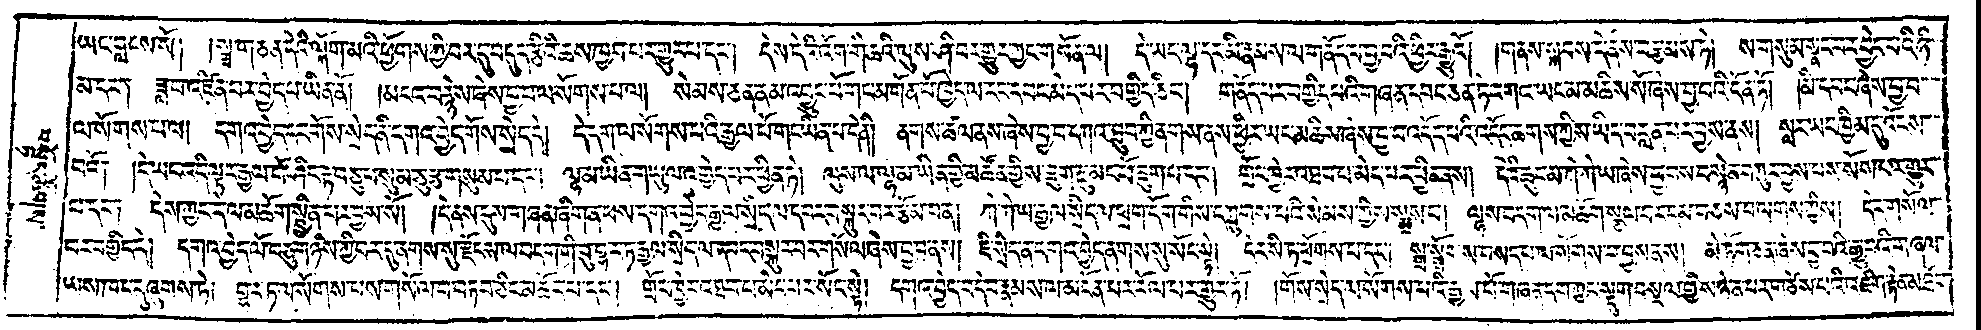

In [4]:
img_idx = 24
for line in etext_pages[img_idx]:
    print(line)

print(images[img_idx])
ShowImage(images[img_idx])

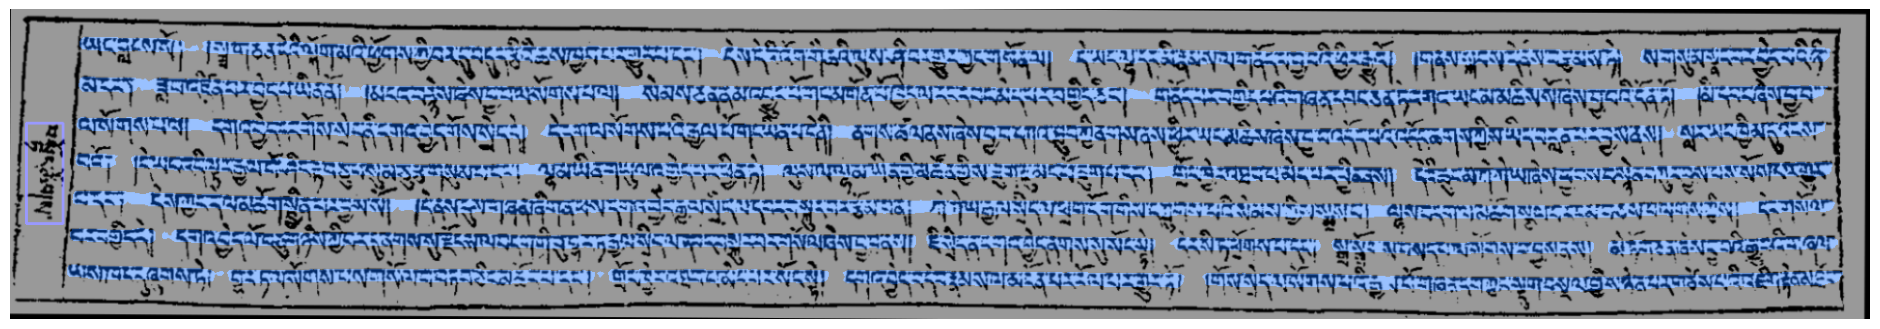

In [5]:
image_name = os.path.basename(images[img_idx]).split(".")[0]
_img = cv2.imread(images[img_idx])

# layout_inference
layout_data, preview_img = layout_inference.predict(_img)
show_image(preview_img)

### Old LinePrediction

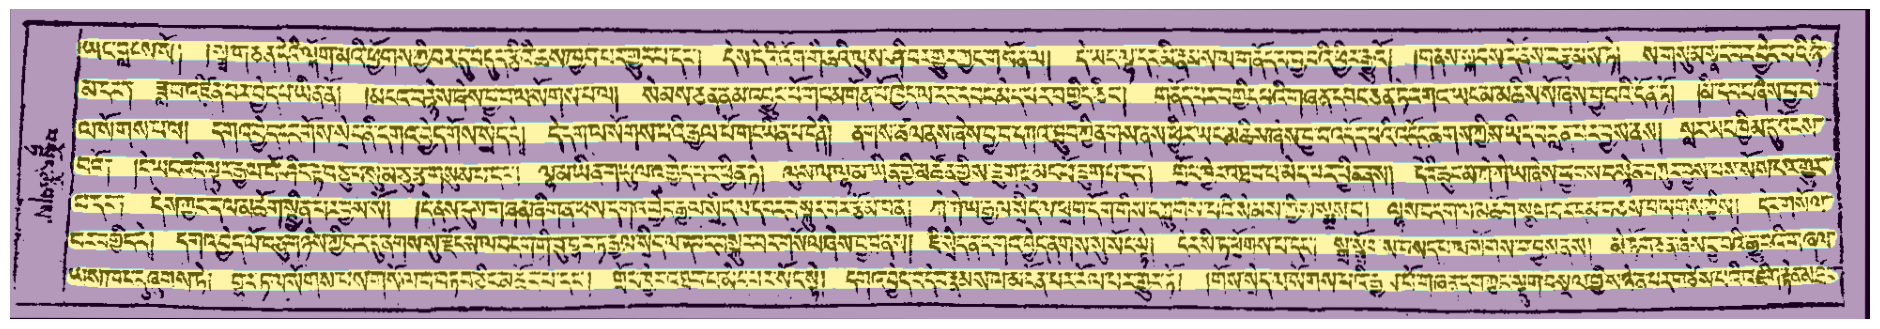

In [10]:
prediction, rotated_image, line_images, sorted_contours, bbox, peaks = line_inference.predict(_img, 0)
show_overlay(rotated_image, prediction)

In [11]:
def pad_line(image: np.array, pad_width: int = 20) -> np.array:
    pad_slice = np.ones(shape=(image.shape[0], pad_width, 3), dtype=np.uint8)
    pad_slice *=255
    padded_line = np.hstack([pad_slice, image, pad_slice])

    return padded_line

line_images = [pad_line(x) for x in line_images]

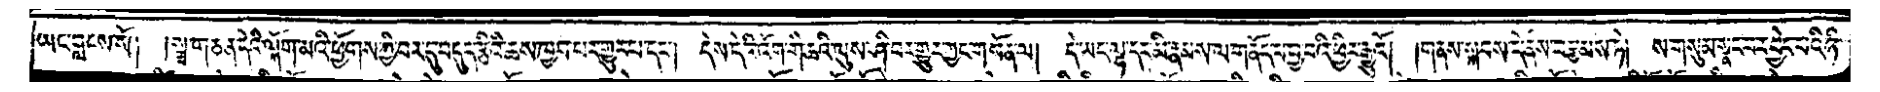

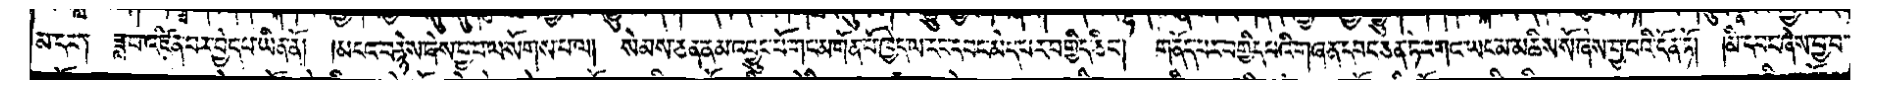

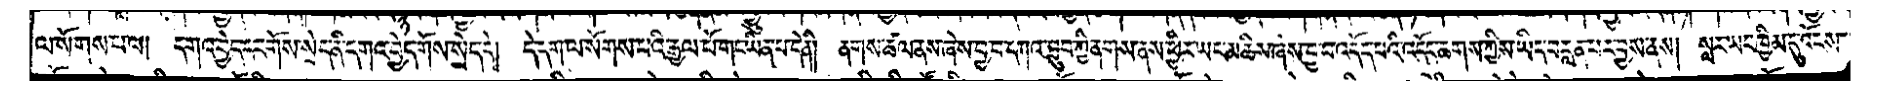

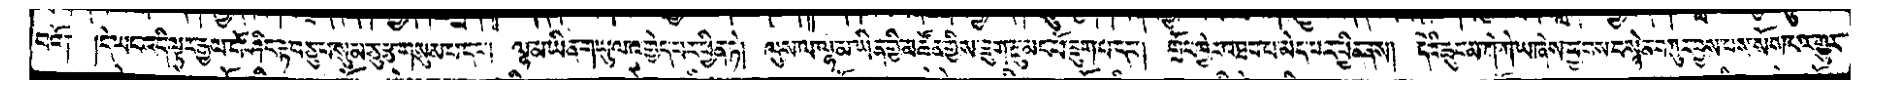

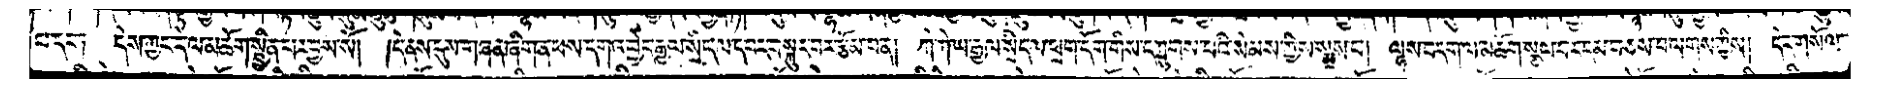

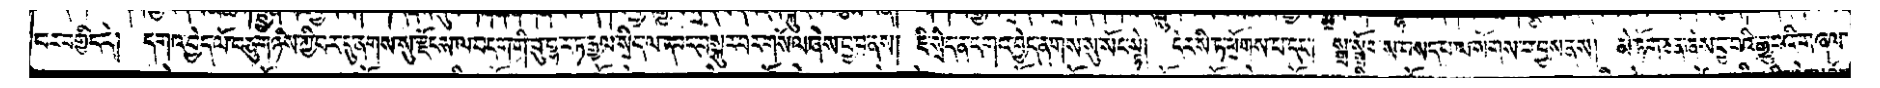

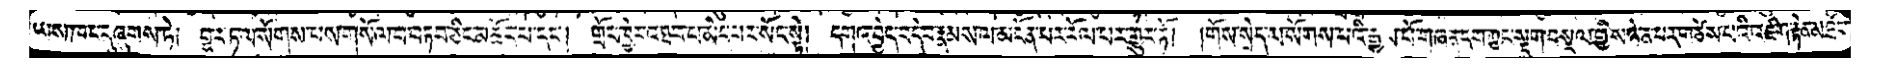

In [12]:
for idx, img in enumerate(line_images):
    show_image(line_images[idx])

#### Layout Prediction

In [3]:
sorted_layout_data = layout_inference.sort_lines(layout_data, group_lines=True)
r_img = rotate_from_angle(_img, layout_data.rotation)
prev_img = r_img.copy()
color = get_random_color()

for line_data in sorted_layout_data.lines:
    color = get_random_color()
    cv2.drawContours(prev_img,[line_data.contour],contourIdx=-1,color=color,thickness=2)

show_image(prev_img) 

NameError: name 'layout_data' is not defined

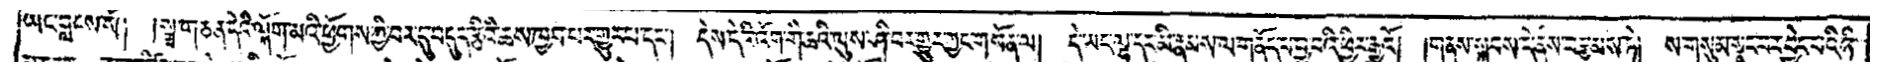

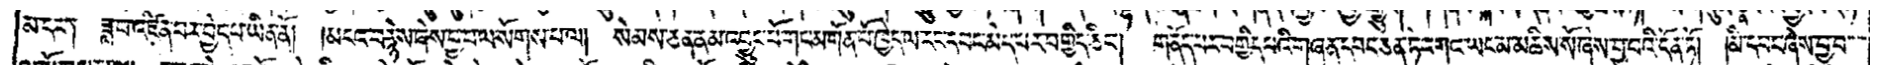

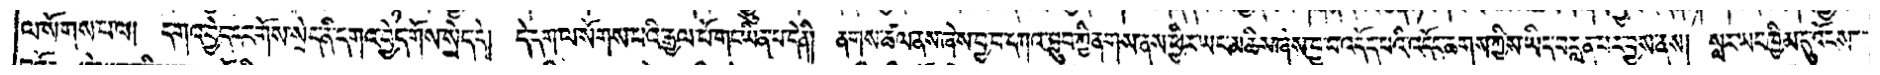

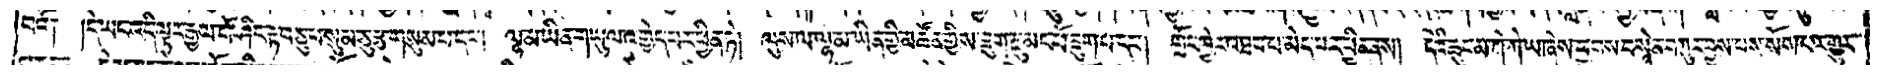

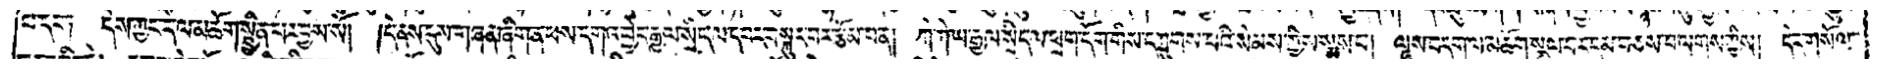

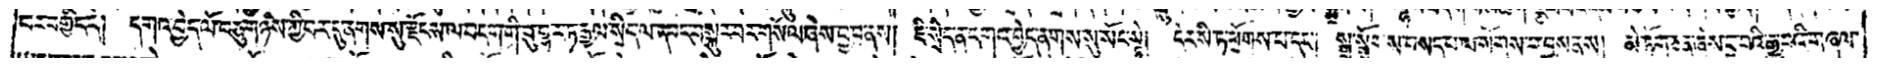

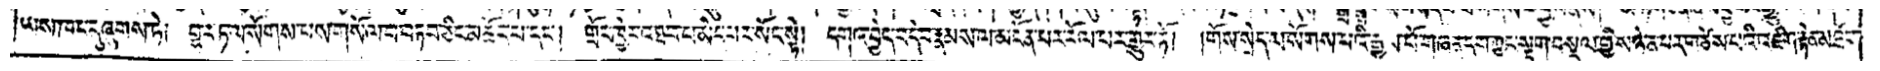

In [14]:
bbox_lines = [get_line_image_from_bbox(r_img, line, x_offset=8, y_offset=0.6) for line in sorted_layout_data.lines]


for idx, img in enumerate(bbox_lines):
    show_image(bbox_lines[idx])

In [11]:
kernel_lines = [get_kernel_line(r_img, x) for x in sorted_layout_data.lines]
kernel_lines = [x[0] for x in kernel_lines]

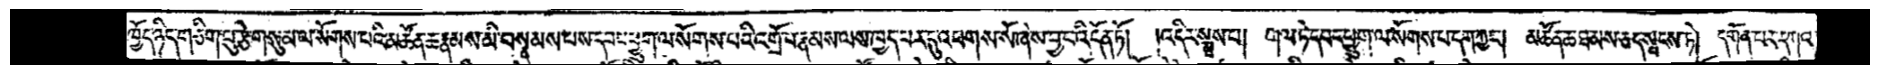

In [12]:
show_image(kernel_lines[0])

In [8]:
np_img_batch = [
            prepare_ocr_image2(
                x, target_width=ocr_inference._input_width, target_height=ocr_inference._input_height
            ) for x in kernel_lines]
            
np_img_batch = np.array(np_img_batch, np.float32)
print(np_img_batch.shape)
predicted_text, raw = ocr_inference.run(np_img_batch, replace_tsheg=" ")
for line in predicted_text:
    #text = text.replace(" ", "")
    #text = text.replace("§", " ")
    if line != "":
        print(line)

(7, 1, 80, 2000)
yang blangs so//sgra gcan de'i lkog ma'i phyogs kyi bar du bdud ktsi 'i chas khyab par gyur pa dang /des de'i rig gi cha'i lus shi bar gyur kyang g.yo n ma/de yang lha dang ri rnams la gnod pa bya ba'i phyir rgyu'o//gnas skabs de nas brtsams te/sa gsum snang bar byed pa'i nyi 
ma dang /zla ba 'dzin par byed pa yin no//mngar brnyes zes pa ba la sogs pa la/sems can nam 'byung po gang mgon po khyed la rang dbang med par bgyid cing /gnod par bgyid pa'i gzhan dbang can ter gar yang ma mchis so zhes bya ba'i don to//mi dbang zhes bya ba 
la sogs pa la/dga' byed dang gos sred ni dga' byed gos sed de/de dag la sogs pa'i rgyal po gang yin pa de ni/nags tshal nas zhes bya ba dka' byab kyi nags nas phyir yang m chim zhes pya ba 'dod pa'i 'dod chags kyis yid brlan par byas nas/slar yang khyim du 'ongs 
ba'o//de yang 'di ltar rgyal po shing rta b bya ba sum cu rtsa gsum pa dang /lha ma yin g.yul 'gyed par phyin te/lus la lha ma yin gyi mtshon gyis zug rngu mang po drug pa dang /gro

In [13]:
def get_components(image: np.array, connectivity: int = 4):
    #connectivity = 4 or 8, check here: https://stackoverflow.com/questions/7088678/4-connected-vs-8-connected-in-connected-component-labeling-what-is-are-the-meri
    image = cv2.bitwise_not(image)
    image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    output = cv2.connectedComponentsWithStats(image, connectivity, cv2.CV_32S)
    numLabels, labels, stats, centroids = output

    return numLabels, labels, stats, centroids

def get_component_info(index: int, stats, centroids):
           
    x = stats[index, cv2.CC_STAT_LEFT]
    y = stats[index, cv2.CC_STAT_TOP]
    w = stats[index, cv2.CC_STAT_WIDTH]
    h = stats[index, cv2.CC_STAT_HEIGHT]
    area = stats[index, cv2.CC_STAT_AREA]
    (cX, cY) = centroids[index]
    return x, y, w, h, cX, cY, area

def filter_components(image: np.array, y_offset: int = 3, area_threshold: int = 6, y_border: bool = True, x_border: bool = False, filter_area: bool = True):

    mask = np.zeros((image.shape[0], image.shape[1]), dtype="uint8")
    numLabels, labels, stats, centroids = get_components(image)

    for compnt_idx in range(0, numLabels):
        x, y, w, h, cX, cY, area = get_component_info(compnt_idx, stats, centroids)

        # component touches the border
        x_pos = x > 0 and x+w < image.shape[1] - 1
        y_pos = y > 0 and y+h < image.shape[0] - 1
        #y_pos = y > 0

        cy_filter = cY > y_offset and cY < image.shape[0] - y_offset
        #keepArea = area > 500 and area < 1500
        area_size = area > area_threshold

        filters = []
        filters.append(cy_filter)
        
        if x_border:
            filters.append(x_pos)

        if y_border:
            filters.append(y_pos)

        if filter_area:
            filters.append(area_size)

        if all(filters):
            componentMask = (labels == compnt_idx).astype("uint8") * 255
            mask = cv2.bitwise_or(mask, componentMask)

    mask = cv2.bitwise_not(mask)
    return mask

In [29]:
test_bbox = bbox_lines[-2]
mask = np.zeros((test_bbox.shape[0], test_bbox.shape[1]), dtype="uint8")
numLabels, labels, stats, centroids = get_components(test_bbox, connectivity=8)

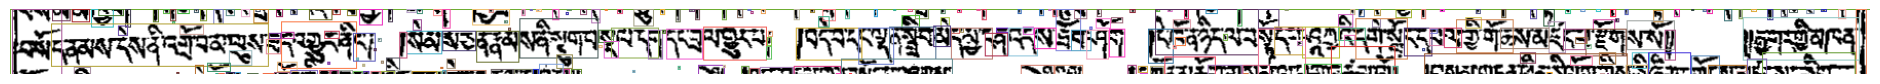

In [30]:
line_viz = test_bbox.copy()

for compnt_idx in range(0, numLabels):
        color = get_random_color()
        x, y, w, h, cX, cY, area = get_component_info(compnt_idx, stats, centroids)

        cv2.rectangle(line_viz, (x,y), (x+w, y+h), color, 1)

show_image(line_viz)

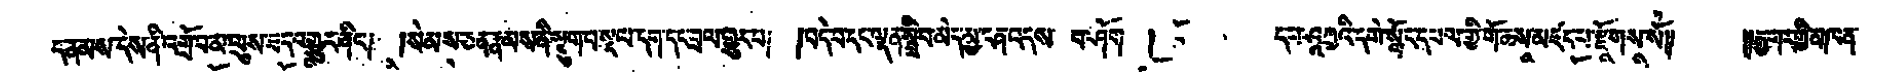

In [28]:
test_bbox = bbox_lines[-2]
filtered_bbox_img = filter_components(test_bbox, y_border=True, x_border=True, filter_area=False, y_offset=1)
filtered_bbox_img = cv2.cvtColor(filtered_bbox_img, cv2.COLOR_GRAY2BGR)
show_image(filtered_bbox_img)

In [9]:
layout_line_images = get_line_images_from_line_data(r_img, sorted_layout_data.lines, dilate_kernel=24, dilate_iterations=16, calculate_iterations=False)
#rev_images = list(reversed(layout_line_images))

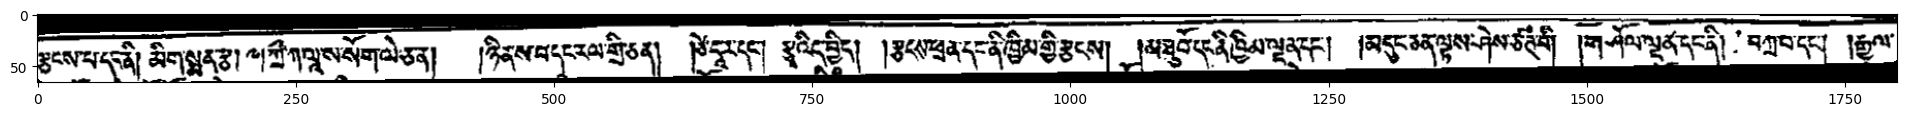

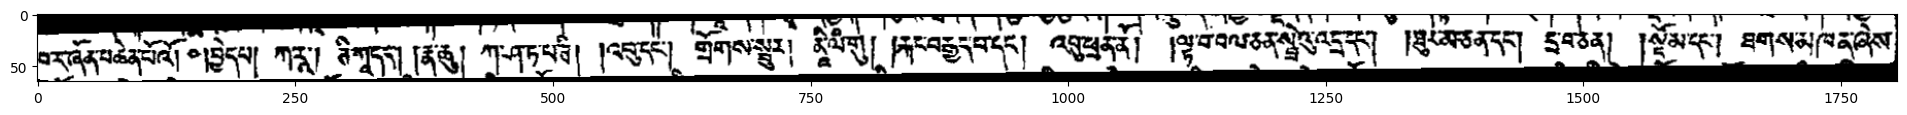

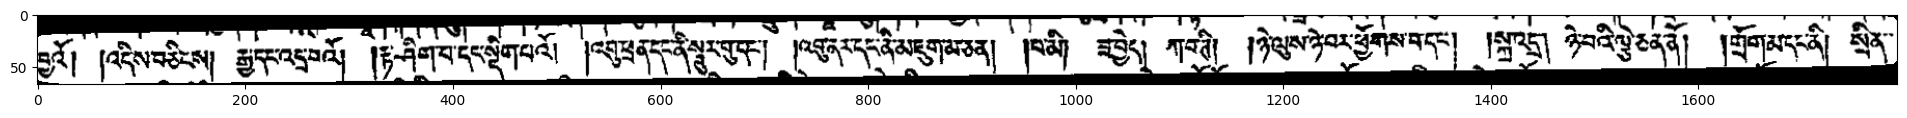

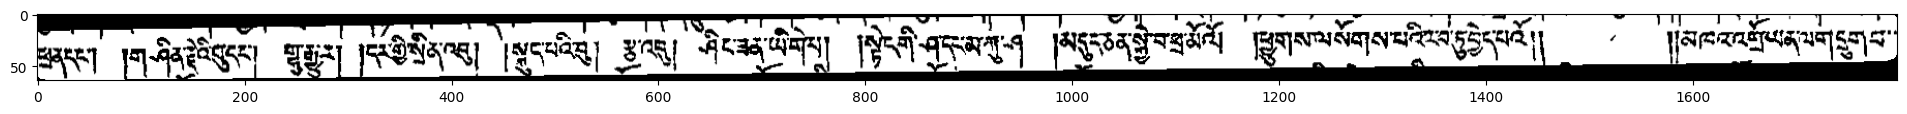

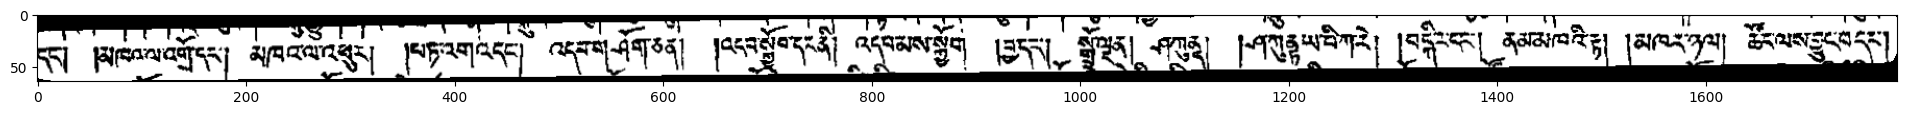

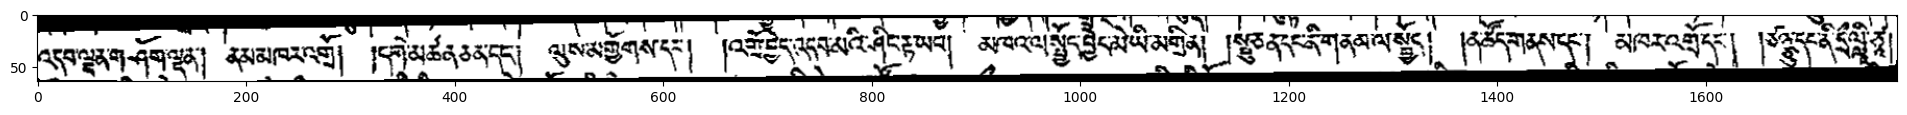

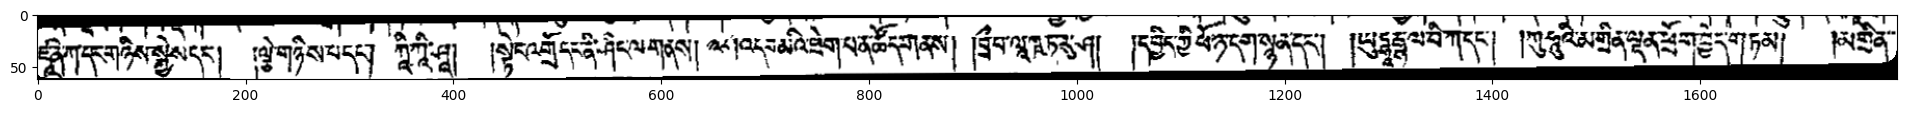

In [10]:
for idx, img in enumerate(layout_line_images):
    show_image(layout_line_images[idx])

In [44]:
test_line_out = "test_line.jpg"
cv2.imwrite(test_line_out, layout_line_images[0])

True

### run the volume

In [4]:
from Exporter import PageXMLExporter

In [5]:
for vol_id in range(1317, 1420):
    #vol_id = "1319"

    test_vol = f"D:\Github\OCR-Inference\Data\W23703\I{vol_id}"
    images = natsorted(glob(f"{test_vol}/*.jpg"))

    etext_file = f"Data/W23703/eText/23703-{vol_id}.json"
    etext_pages = get_json(etext_file)
    etext_pages = list(etext_pages.values())
    etext_pages = [x for x in etext_pages if x != [""]]

    print(f"Images: {len(images)}, Pages: {len(etext_pages)}")

    dataset_out = os.path.join(test_vol, "DatasetFebruary2024")

    if os.path.exists(dataset_out):
        shutil.rmtree(dataset_out)

    dataset_lines_out = os.path.join(dataset_out, "lines")
    dataset_labels_out = os.path.join(dataset_out, "transcriptions")
    create_dir(dataset_out)
    create_dir(dataset_lines_out)
    create_dir(dataset_labels_out)

    xml_out_dir = os.path.join(dataset_out, "xml")
    xml_out = os.path.join(xml_out_dir, "page")

    xml_exporter = PageXMLExporter(xml_out)

    create_dir(xml_out_dir)
    create_dir(xml_out)

    mismatch_pages = []

    for idx, (image, page_text) in tqdm(enumerate(zip(images, etext_pages)), total=len(images)):
        # layout_inference
        try:
            image_name = os.path.basename(image).split(".")[0]
            _img = cv2.imread(image)

        except FileExistsError as e:
            print.error(f"Cant read file at provided location: {image}, {e}")
            continue


        # layout_inference
        layout_data, _ = layout_inference.predict(_img)
        sorted_layout_data = layout_inference.sort_lines(layout_data, calculate=True, group_lines=True)

        #print(f"{image_name} => rotation: {layout_data.rotation}")

        r_img = rotate_from_angle(_img, layout_data.rotation)
        #line_images = [get_line_image_from_bbox(r_img, line, x_offset=8) for line in sorted_layout_data.lines]
        line_images = [get_kernel_line(r_img, x) for x in sorted_layout_data.lines]
        line_images = [x[0] for x in line_images]


        if len(line_images) == len(page_text):
            #img_out = f"{out_dir}/{image_name}.jpg"
            #cv2.imwrite(img_out, r_img)
            #xml_exporter.export(r_img, image_name, )

            for s_idx, (l_img, l_lbl) in enumerate(zip(line_images, page_text)):
                
                # xml output
                img_out = f"{xml_out_dir}/{image_name}.jpg"
                cv2.imwrite(img_out, r_img)
                xml_exporter.export(r_img, image_name, sorted_layout_data, page_text)
                

                #direct line-txt output
                img_out = f"{dataset_lines_out}/{image_name}_{s_idx}.jpg"
                lbl_out = f"{dataset_labels_out}/{image_name}_{s_idx}.txt"
            
                cv2.imwrite(img_out, l_img)

                with open(lbl_out, "w", encoding="utf-8") as f:
                    f.write(l_lbl)
                
        else:
            #print("page-line mismatch")
            mismatch_pages.append(image)


    print(f"Mismatched pages: {len(mismatch_pages)}")

    mismatch_pages_out = f"{dataset_out}/page_mismatches.txt"

    with open(mismatch_pages_out, "w", encoding="utf-8") as f:
        for p in mismatch_pages:
            f.write(f"{p}\n")

Images: 514, Pages: 514


  4%|▎         | 19/514 [00:17<05:18,  1.56it/s]d:\Github\OCR-Inference\venv\lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
d:\Github\OCR-Inference\venv\lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
100%|██████████| 514/514 [07:40<00:00,  1.12it/s]


Mismatched pages: 32
Images: 548, Pages: 548


100%|██████████| 548/548 [05:47<00:00,  1.58it/s]


Mismatched pages: 30
Images: 586, Pages: 586


100%|██████████| 586/586 [07:17<00:00,  1.34it/s]


... (12 outputs left out)

Mismatched pages: 26
Images: 730, Pages: 730


100%|██████████| 730/730 [07:20<00:00,  1.66it/s]


Mismatched pages: 37
Images: 552, Pages: 552


 92%|█████████▏| 510/552 [05:37<00:27,  1.53it/s]

In [9]:
mismatch_pages = []

for idx, (image, page_text) in tqdm(enumerate(zip(images, etext_pages)), total=len(images)):
    # layout_inference
    try:
        image_name = os.path.basename(image).split(".")[0]
        _img = cv2.imread(image)

    except FileExistsError as e:
        print.error(f"Cant read file at provided location: {image}, {e}")
        continue


    # layout_inference
    layout_data, _ = layout_inference.predict(_img)
    sorted_layout_data = layout_inference.sort_lines(layout_data, calculate=True, group_lines=True)
    r_img = rotate_from_angle(_img, layout_data.rotation)
    line_images = [get_line_image_from_bbox(r_img, line, x_offset=8) for line in sorted_layout_data.lines]

    if len(line_images) == len(page_text):
        #img_out = f"{out_dir}/{image_name}.jpg"
        #cv2.imwrite(img_out, r_img)
        #xml_exporter.export(r_img, image_name, )

        for s_idx, (l_img, l_lbl) in enumerate(zip(line_images, page_text)):
            
            """img_out = f"{out_dir}/{image_name}.jpg"
            cv2.imwrite(img_out, r_img)
            xml_exporter.export(r_img, image_name, sorted_layout_data, page_text)
            """

            #direct line-txt output
            
            img_out = f"{dataset_lines_out}/{image_name}_{s_idx}.jpg"
            lbl_out = f"{dataset_labels_out}/{image_name}_{s_idx}.txt"
        
            cv2.imwrite(img_out, l_img)

            with open(lbl_out, "w", encoding="utf-8") as f:
                f.write(l_lbl)
            
    else:
        #print("page-line mismatch")
        mismatch_pages.append(image)


print(f"Mismatched pages: {len(mismatch_pages)}")

mismatch_pages_out = f"{dataset_out}/page_mismatches.txt"

with open(mismatch_pages_out, "w", encoding="utf-8") as f:
    for p in mismatch_pages:
        f.write(f"{p}\n")

100%|██████████| 586/586 [05:25<00:00,  1.80it/s]

Mismatched pages: 31
